In [1]:
import os
import cv2
import random
import pandas as pd
import ast
import wfdb
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
path = "" # Fill with your own path
image_output_dir = "" # Fill with your own path
sampling_rate = 500 # 500 for 500hz
os.makedirs(path, exist_ok=True)

# Load annotation data
Y = pd.read_csv(path + 'ptbxl_database.csv', index_col='ecg_id') # to extract ecg id
Y.scp_codes = Y.scp_codes.apply(lambda x: ast.literal_eval(x))

In [3]:
train_split = 0.7
val_split = 0.15
test_split = 0.15

In [4]:
indices = Y.index.tolist()
n_total = len(indices)
n_train = int(train_split * n_total)
n_val = int(val_split * n_total)

train_idx = indices[:n_train]
val_idx = indices[n_train:n_train+n_val]
test_idx = indices[n_train+n_val:]

splits_dict = {
    "train": train_idx,
    "val": val_idx,
    "test": test_idx
}

In [5]:
from PIL import Image, ImageEnhance
def degrade_ecg_image(img):
    """
    img: numpy.ndarray (BGR, uint8)
    """
    img = img.copy()

    # if random.random() < 0.5:
    #     noise = np.random.normal(0, 25, img.shape).astype(np.int16)
    #     img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    # if random.random() < 0.3:
    #     k = random.choice([3, 5])
    #     img = cv2.GaussianBlur(img, (k, k), 0)

    # if random.random() < 0.3:
    #     for _ in range(random.randint(1, 3)):
    #         center = (
    #             random.randint(0, img.shape[1] - 1),
    #             random.randint(0, img.shape[0] - 1),
    #         )
    #         radius = random.randint(3, 10)
    #         color = random.choice([(100, 100, 100), (200, 200, 200)])
    #         cv2.circle(img, center, radius, color, -1)

    if random.random() < 0.7:
        pil_img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        pil_img = ImageEnhance.Brightness(pil_img).enhance(random.uniform(0.7, 1.3))
        pil_img = ImageEnhance.Contrast(pil_img).enhance(random.uniform(0.7, 1.3))
        img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    return img

In [6]:
def fig_to_image(fig):
    fig.canvas.draw()

    # Get RGBA buffer
    buf = np.asarray(fig.canvas.buffer_rgba())

    # Convert RGBA → RGB
    img = buf[..., :3].copy()

    return img


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os


def plot_ecg_paper_image_3x4(signal,
                             fs=500, duration=10,
                             pixels_per_small=4,
                             row_mV_span=3,
                             top_margin=80, left_margin=40,
                             line_width=1,
                             save_path=None, label=None,
                             randomize_baseline=True,
                             baseline_shift_range=0.2,
                             save_yolo_labels=True,
                             draw_boxes=False):
    assert signal.ndim == 2 and signal.shape[1] >= 12, "signal must be (samples, >=12 leads)"

    # Standard ECG paper settings
    small_sec = 0.04  # 1 mm = 0.04s
    small_mV = 0.10   # 1 mm = 0.10 mV

    # Define lead order
    lead_order = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF',
                  'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

    # Geometry
    grid_duration = 2.5
    grid_smalls_per_lead = int(grid_duration / small_sec)
    rhythm_smalls_per_lead = int(duration / small_sec)

    pixels_width = (grid_smalls_per_lead * 4 + 1) * pixels_per_small
    pixels_per_mV = pixels_per_small / small_mV
    row_height_px = int(round(pixels_per_mV * row_mV_span))
    rows = 4
    pixels_height = rows * row_height_px

    W = int(round(left_margin + pixels_width + left_margin))
    H = int(round(top_margin + pixels_height + top_margin))

    dpi = 100
    fig = plt.figure(figsize=(W/dpi, H/dpi), dpi=dpi)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.invert_yaxis()
    ax.axis('off')

    # Background color
    bg_color = (255/255, 228/255, 235/255)
    fig.patch.set_facecolor(bg_color)
    ax.set_facecolor(bg_color)

    # Vertical grid lines - start from left_margin
    for k in range(int((pixels_width) / pixels_per_small) + 2):
        x = left_margin + k * pixels_per_small
        if k % 5 == 0:
            ax.plot([x, x], [0, H-1],
                   color=(220/255, 80/255, 120/255), linewidth=2)
        else:
            ax.plot([x, x], [0, H-1],
                   color=(255/255, 200/255, 215/255), linewidth=1)

    # Horizontal grid lines - start from y=0
    for k in range(int(H / pixels_per_small) + 1):
        y = k * pixels_per_small
        if y % (5 * pixels_per_small) == 0:
            ax.plot([left_margin, left_margin + pixels_width + 1], [y, y],
                   color=(220/255, 80/255, 120/255), linewidth=2)
        else:
            ax.plot([left_margin, left_margin + pixels_width + 1], [y, y],
                   color=(255/255, 200/255, 215/255), linewidth=1)

    # Precompute X positions
    n_samples_per_grid_lead = int(grid_duration * fs) # 1250 or 5000 samples
    xs_grid = np.arange(n_samples_per_grid_lead) * (pixels_per_small * grid_smalls_per_lead) / max(1, n_samples_per_grid_lead - 1) # maps each sample index to an exact horizontal pixel

    # Mapping lead positions
    # (row, column) -> lead index
    display_map = {
        (0, 0): 0, (0, 1): 3, (0, 2): 6, (0, 3): 9,
        (1, 0): 1, (1, 1): 4, (1, 2): 7, (1, 3): 10,
        (2, 0): 2, (2, 1): 5, (2, 2): 8, (2, 3): 11
    }
    
    yolo_labels = []

    # Generate random baseline shifts
    if randomize_baseline:
        baseline_shifts = np.random.uniform(-baseline_shift_range,
                                            baseline_shift_range,
                                            size=12) * pixels_per_mV
    else:
        baseline_shifts = np.zeros(12)

    for row in range(3):
        base_y = top_margin + row * row_height_px + row_height_px / 2
        for col in range(4):
            lead_idx = display_map[(row, col)] # get lead index based on row and column index
            x_offset = left_margin + col * (grid_smalls_per_lead * pixels_per_small)
            yvals = signal[:n_samples_per_grid_lead, lead_idx]

            x_coords = x_offset + xs_grid # xs_grid is the end of the x coordinates for one lead based on pixels
            y_coords = base_y - yvals * pixels_per_mV + baseline_shifts[lead_idx] # base_y - because y increases downwards. positive amplitude goes up

            ax.plot(x_coords, y_coords, color='black', linewidth=line_width) # keeps em as floats and use anti aliasing by matplotlib

            # Calculate bounding box
            x_min, x_max = x_coords.min(), x_coords.max()
            y_min, y_max = y_coords.min(), y_coords.max()

            # Label
            lab_x = x_offset + int(0.02 * pixels_per_small * grid_smalls_per_lead)
            lab_y = base_y - int(1 * pixels_per_mV)
            ax.text(lab_x, lab_y, lead_order[lead_idx], fontsize=8, color='black')

            # Normalize for YOLO
            x_center = (x_min + x_max) / 2 / W
            y_center = (y_min + y_max) / 2 / H
            width = (x_max - x_min) / W
            height = (y_max - y_min) / H

            yolo_labels.append(f"{lead_idx} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}")

            if draw_boxes:
                rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                        linewidth=1, edgecolor='blue', facecolor='none', linestyle='solid',zorder=10)
                ax.add_patch(rect)

    # Rhythm strip (Lead II)
    rhythm_lead_idx = 1
    n_samples_rhythm = int(duration * fs)
    xs_rhythm = np.arange(n_samples_rhythm) * (pixels_per_small * rhythm_smalls_per_lead) / max(1, n_samples_rhythm - 1)

    base_y = top_margin + 3 * row_height_px + row_height_px / 2 # fourth row
    x_offset = left_margin
    yvals = signal[:n_samples_rhythm, rhythm_lead_idx]
    print(yvals)

    # Use floating point coordinates for smoother lines
    x_coords = x_offset + xs_rhythm
    y_coords = base_y - yvals * pixels_per_mV + (baseline_shifts[rhythm_lead_idx] if randomize_baseline else 0)

    ax.plot(x_coords, y_coords, color='black', linewidth=line_width) 

    # Calculate bounding box
    x_min, x_max = x_coords.min(), x_coords.max()
    y_min, y_max = y_coords.min(), y_coords.max()

    lab_x = x_offset + int(0.02 * pixels_per_small * rhythm_smalls_per_lead)
    lab_y = base_y - int(1.0 * pixels_per_mV)
    ax.text(lab_x, lab_y, "Lead II (Rhythm)", fontsize=8, color='black')

    # Normalize for YOLO
    x_center = (x_min + x_max) / 2 / W
    y_center = (y_min + y_max) / 2 / H
    width = (x_max - x_min) / W
    height = (y_max - y_min) / H

    rhythm_class_id = 12
    yolo_labels.append(f"{rhythm_class_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}")

    if draw_boxes:
        rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                linewidth=1, edgecolor='blue', facecolor='none', linestyle='solid',zorder=10)
        ax.add_patch(rect)

    # Add optional label
    if label is not None:
        ax.text(W // 2 - 40, 4, str(label), fontsize=10, color='black')

    # Save image + YOLO labels
    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches=None, pad_inches=0)
        if save_yolo_labels:
            label_path = save_path.replace("images", "labels").replace(".jpg", ".txt")
            os.makedirs(os.path.dirname(label_path), exist_ok=True)
            with open(label_path, "w") as f:
                f.write("\n".join(yolo_labels))
        plt.close(fig)
    img = fig_to_image(fig)
    img = degrade_ecg_image(img)
    return img

[-0.235 -0.235 -0.235 ... -0.02  -0.02  -0.02 ]


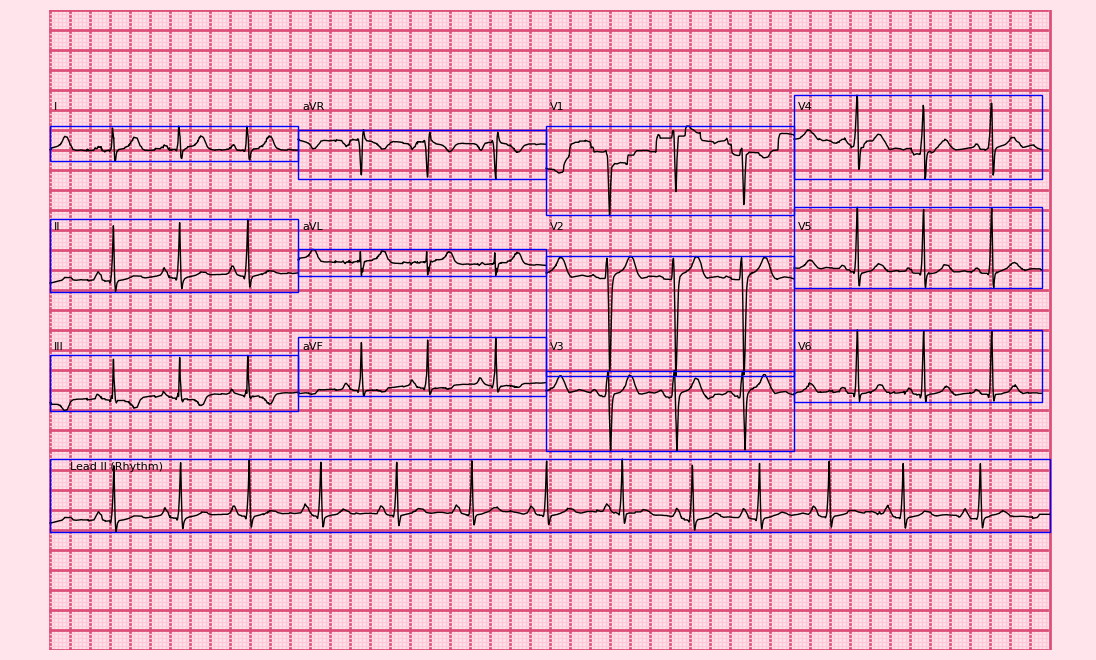

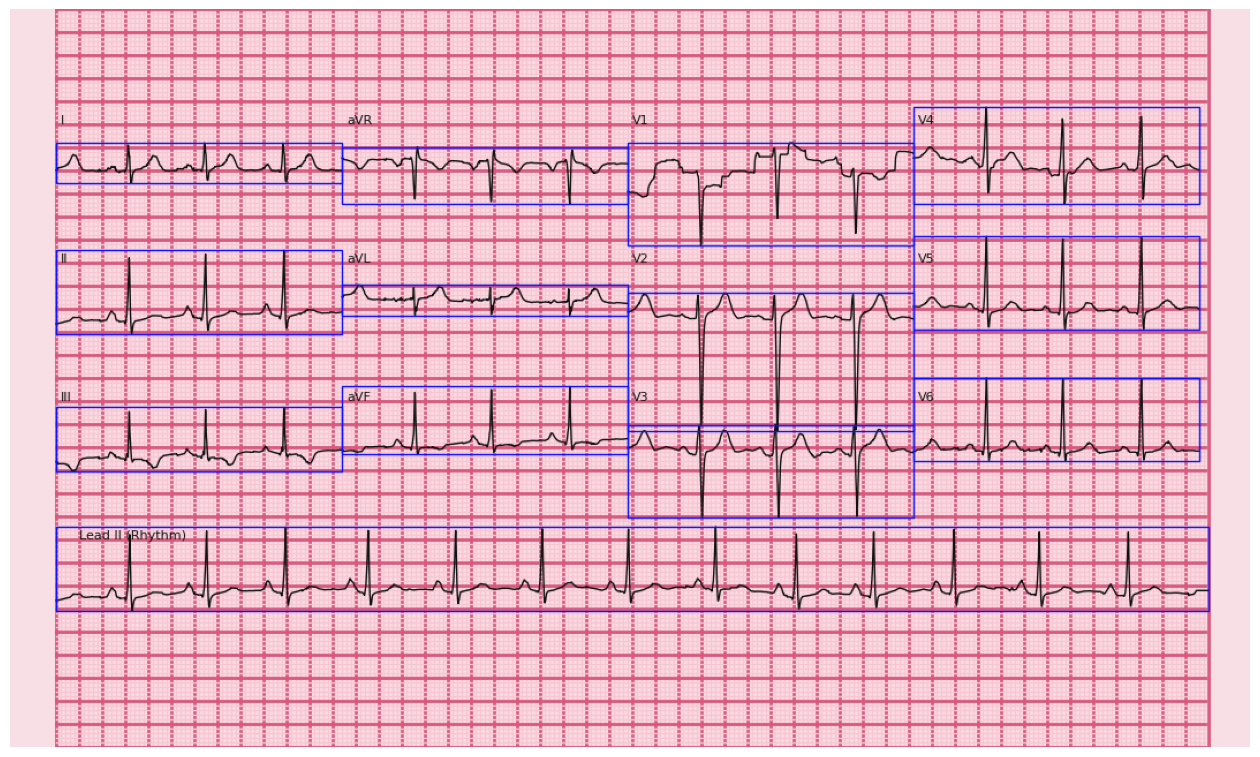

In [10]:
# row = Y.iloc[3]
row = Y.iloc[5]
record_path = path + row.filename_hr

signal, meta = wfdb.rdsamp(record_path)

img = plot_ecg_paper_image_3x4(signal, fs=sampling_rate, duration=10, pixels_per_small=4, row_mV_span=3, draw_boxes=True)
plt.figure(figsize=(16, 24))
plt.imshow(img)
plt.axis("off")
plt.show()

In [7]:
# Create YOLO folder structure
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(image_output_dir, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(image_output_dir, split, "labels"), exist_ok=True)


In [8]:
import time
import gc
for split_name, split_indices in splits_dict.items():
    print(f"\nProcessing {split_name} split ({len(split_indices)} samples)")
    
    # Check which files already exist
    existing_images = set()
    images_dir = os.path.join(image_output_dir, split_name, "images")
    if os.path.exists(images_dir):
        existing_images = {int(f.replace('.jpg', '')) for f in os.listdir(images_dir) if f.endswith('.jpg')}
    
    # Filter out already processed IDs
    remaining_indices = [idx for idx in split_indices if idx not in existing_images]
    
    print(f"Already completed: {len(existing_images)}")
    print(f"Remaining: {len(remaining_indices)}")
    
    if len(remaining_indices) == 0:
        print(f"{split_name} split already complete!")
        continue
    
    count = 0
    
    for ecg_id in tqdm(remaining_indices, desc=f"Generating {split_name} images"):
        try:
            # Get the filename path from the database
            filename = Y.loc[ecg_id, 'filename_hr'] if sampling_rate == 500 else Y.loc[ecg_id, 'filename_lr']
            
            # Load the ECG signal
            signal_data = wfdb.rdsamp(os.path.join(path, filename))
            signal = signal_data[0]  # Extract the signal array (samples, 12 leads)
            
            # Define save path
            save_path = os.path.join(image_output_dir, split_name, "images", f"{ecg_id}.jpg")
            
            # Generate the ECG paper image with YOLO labels
            plot_ecg_paper_image_3x4(
                signal=signal,
                fs=sampling_rate,
                duration=10,
                save_path=save_path,
                label=ecg_id,
                randomize_baseline=True,
                save_yolo_labels=True,
                draw_boxes=False
            )
            del signal, signal_data
            plt.close('all')
            # gc.collect()
            
            count += 1
            if count % 100 == 0:
                print(f"Processed {count} images in {split_name} split...")
                time.sleep(5)
            
        except Exception as e:
            print(f"\nError processing ECG ID {ecg_id}: {str(e)}")
            continue

print(f"Train: {len(train_idx)} samples")
print(f"Val: {len(val_idx)} samples")
print(f"Test: {len(test_idx)} samples")


Processing train split (15259 samples)
Already completed: 15259
Remaining: 0
train split already complete!

Processing val split (3269 samples)
Already completed: 3269
Remaining: 0
val split already complete!

Processing test split (3271 samples)
Already completed: 1705
Remaining: 1566


Generating test images:   6%|▋         | 99/1566 [00:21<04:56,  4.95it/s]

Processed 100 images in test split...


Generating test images:  13%|█▎        | 199/1566 [00:48<05:00,  4.54it/s]

Processed 200 images in test split...


Generating test images:  19%|█▉        | 299/1566 [01:18<05:41,  3.71it/s]

... (23 outputs left out)

Generating test images:  96%|█████████▌| 1499/1566 [06:45<00:13,  5.05it/s]

Processed 1500 images in test split...


Generating test images: 100%|██████████| 1566/1566 [07:04<00:00,  3.69it/s]


Train: 15259 samples
Val: 3269 samples
Test: 3271 samples
